In [1]:
%pip -q install conllu sklearn-crfsuite scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
from collections import Counter
import json
import time
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn_crfsuite
from sklearn_crfsuite import metrics as crf_metrics

from conllu import parse_incr
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Imports ready.")

Imports ready.


In [3]:
from pathlib import Path
import subprocess

# Use the SAME English EWT dataset as hmm-pos-tagger.ipynb.
# This avoids cloning 13 separate treebanks and keeps both models comparable.
DATA_DIR_CANDIDATES = [
    Path("/content/UD_English-EWT"),
    Path("/kaggle/working/UD_English-EWT"),
    Path("/kaggle/input/ud-english-ewt"),
    Path("./UD_English-EWT"),
]

def has_splits(path):
    return all((path / f"en_ewt-ud-{split}.conllu").exists()
               for split in ["train", "dev", "test"])

DATA_DIR = next((p for p in DATA_DIR_CANDIDATES if has_splits(p)), None)

if DATA_DIR is None:
    # Match the HMM notebook's download location where possible.
    target = Path("/content/UD_English-EWT") if Path("/content").exists() else Path("./UD_English-EWT")
    if not target.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/UniversalDependencies/UD_English-EWT.git", str(target)],
            check=True,
        )
    DATA_DIR = target

if not has_splits(DATA_DIR):
    raise FileNotFoundError(
        f"Could not find train/dev/test CoNLL-U files in {DATA_DIR.resolve()}. "
        "Check that the UD_English-EWT dataset downloaded correctly."
    )

print("Using dataset:", DATA_DIR.resolve())
print("Dataset files:", sorted(p.name for p in DATA_DIR.glob("*.conllu")))


Using dataset: C:\Users\User\NLP\nlp project\UD_English-EWT
Dataset files: ['en_ewt-ud-dev.conllu', 'en_ewt-ud-test.conllu', 'en_ewt-ud-train.conllu']


In [4]:
def load_conllu(path):
    sentences, tag_sequences = [], []

    with open(path, "r", encoding="utf-8") as f:
        for sentence in parse_incr(f):
            words, tags = [], []
            for token in sentence:
                token_id = token.get("id")
                # Skip multiword-token ranges and empty nodes.
                if not isinstance(token_id, int):
                    continue
                word = token.get("form")
                tag = token.get("upos")
                if word is None or tag is None:
                    continue
                words.append(word)
                tags.append(tag)

            if words:
                assert len(words) == len(tags)
                sentences.append(words)
                tag_sequences.append(tags)

    return sentences, tag_sequences


train_words, train_tags = load_conllu(DATA_DIR / "en_ewt-ud-train.conllu")
dev_words, dev_tags = load_conllu(DATA_DIR / "en_ewt-ud-dev.conllu")
test_words, test_tags = load_conllu(DATA_DIR / "en_ewt-ud-test.conllu")

if not train_words or not dev_words or not test_words:
    raise RuntimeError("One or more EWT splits are empty. Check the dataset files.")

source_df = pd.DataFrame([
    {"split": split, "treebank": "English-EWT", "file": f"en_ewt-ud-{split}.conllu",
     "sentences": len(words), "tokens": sum(len(s) for s in words)}
    for split, words in [("train", train_words), ("dev", dev_words), ("test", test_words)]
])
display(source_df)

def split_summary(name, words, tags):
    return {
        "split": name,
        "treebank_files": 1,
        "sentences": len(words),
        "tokens": sum(len(s) for s in words),
        "unique_UPOS_tags": len({tag for seq in tags for tag in seq}),
    }

dataset_summary = pd.DataFrame([
    split_summary("train", train_words, train_tags),
    split_summary("dev", dev_words, dev_tags),
    split_summary("test", test_words, test_tags),
])
display(dataset_summary)

print("Dataset: UD_English-EWT (same splits as the HMM notebook)")
print("Example words:", train_words[0])
print("Example UPOS tags:", train_tags[0])


,split,treebank,file,sentences,tokens
0,train,English-EWT,en_ewt-ud-train.conllu,12544,204578
1,dev,English-EWT,en_ewt-ud-dev.conllu,2001,25148
2,test,English-EWT,en_ewt-ud-test.conllu,2077,25094


,split,treebank_files,sentences,tokens,unique_UPOS_tags
0,train,1,12544,204578,17
1,dev,1,2001,25148,17
2,test,1,2077,25094,17


Dataset: UD_English-EWT (same splits as the HMM notebook)
Example words: ['Al', '-', 'Zaman', ':', 'American', 'forces', 'killed', 'Shaikh', 'Abdullah', 'al', '-', 'Ani', ',', 'the', 'preacher', 'at', 'the', 'mosque', 'in', 'the', 'town', 'of', 'Qaim', ',', 'near', 'the', 'Syrian', 'border', '.']
Example UPOS tags: ['PROPN', 'PUNCT', 'PROPN', 'PUNCT', 'ADJ', 'NOUN', 'VERB', 'PROPN', 'PROPN', 'PROPN', 'PUNCT', 'PROPN', 'PUNCT', 'DET', 'NOUN', 'ADP', 'DET', 'NOUN', 'ADP', 'DET', 'NOUN', 'ADP', 'PROPN', 'PUNCT', 'ADP', 'DET', 'ADJ', 'NOUN', 'PUNCT']


In [5]:
tag_counts = Counter(tag for sentence in train_tags for tag in sentence)
TAG_SET = sorted(tag_counts)

print("Tags observed in training:", len(TAG_SET))
print(TAG_SET)
display(pd.DataFrame(tag_counts.most_common(), columns=["UPOS tag", "Training token count"]))

unseen_dev = sorted({t for s in dev_tags for t in s} - set(TAG_SET))
unseen_test = sorted({t for s in test_tags for t in s} - set(TAG_SET))
print("Tags absent from train but present in dev:", unseen_dev)
print("Tags absent from train but present in test:", unseen_test)

Tags observed in training: 17
['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN', 'NUM', 'PART', 'PRON', 'PROPN', 'PUNCT', 'SCONJ', 'SYM', 'VERB', 'X']


,UPOS tag,Training token count
0,NOUN,34751
1,PUNCT,23596
2,VERB,22576
3,PRON,18678
4,ADP,17714
5,DET,16299
6,ADJ,13136
7,AUX,12815
8,PROPN,12620
9,ADV,10172


Tags absent from train but present in dev: []
Tags absent from train but present in test: []


In [6]:
def word_features(word):
    """Return a dictionary of orthographic features for a single word."""
    return {
        "lower": word.lower(),
        "isupper": word.isupper(),
        "istitle": word.istitle(),
        "isdigit": word.isdigit(),
        "hasdigit": any(c.isdigit() for c in word),
        "hashyphen": "-" in word,
        "prefix1": word[:1].lower(),
        "prefix2": word[:2].lower(),
        "prefix3": word[:3].lower(),
        "prefix4": word[:4].lower(),
        "suffix1": word[-1:].lower(),
        "suffix2": word[-2:].lower(),
        "suffix3": word[-3:].lower(),
        "suffix4": word[-4:].lower(),
    }


def sentence_features(sentence, i):
    """
    Extract CRF features for the token at position *i* in *sentence*.
    Context window: two tokens to the left and two to the right.
    """
    word = sentence[i]
    feats = {"bias": 1.0}

    # Current token.
    feats.update({f"0:{k}": v for k, v in word_features(word).items()})

    # Left context.
    if i >= 1:
        feats.update({f"-1:{k}": v for k, v in word_features(sentence[i - 1]).items()})
    else:
        feats["BOS"] = True  # Beginning of sentence.

    if i >= 2:
        feats.update({f"-2:{k}": v for k, v in word_features(sentence[i - 2]).items()})

    # Right context.
    if i < len(sentence) - 1:
        feats.update({f"+1:{k}": v for k, v in word_features(sentence[i + 1]).items()})
    else:
        feats["EOS"] = True  # End of sentence.

    if i < len(sentence) - 2:
        feats.update({f"+2:{k}": v for k, v in word_features(sentence[i + 2]).items()})

    return feats


def extract_features(sentences):
    """Convert a list of word-sequences into CRF feature sequences."""
    return [
        [sentence_features(sentence, i) for i in range(len(sentence))]
        for sentence in sentences
    ]


print("Feature functions defined.")
# Sanity: show features for the first word of the first training sentence.
print("\nSample features for first token of first training sentence:")
sample = sentence_features(train_words[0], 0)
for k, v in list(sample.items())[:10]:
    print(f"  {k!r}: {v!r}")

Feature functions defined.

Sample features for first token of first training sentence:
  'bias': 1.0
  '0:lower': 'al'
  '0:isupper': False
  '0:istitle': True
  '0:isdigit': False
  '0:hasdigit': False
  '0:hashyphen': False
  '0:prefix1': 'a'
  '0:prefix2': 'al'
  '0:prefix3': 'al'


In [7]:
print("Extracting features ...")
start = time.perf_counter()

X_train = extract_features(train_words)
X_dev   = extract_features(dev_words)
X_test  = extract_features(test_words)

# sklearn-crfsuite expects plain lists of label strings.
y_train = train_tags
y_dev   = dev_tags
y_test  = test_tags

feature_time = time.perf_counter() - start
print(f"Feature extraction done in {feature_time:.1f} seconds.")
print(f"Training sentences : {len(X_train):,}")
print(f"Dev sentences      : {len(X_dev):,}")
print(f"Test sentences     : {len(X_test):,}")

Extracting features ...
Feature extraction done in 9.3 seconds.
Training sentences : 12,544
Dev sentences      : 2,001
Test sentences     : 2,077


In [8]:
# Default hyperparameters — will be refined in the next cell.
C1 = 0.1
C2 = 0.1
MAX_ITER = 100

crf = sklearn_crfsuite.CRF(
    algorithm="lbfgs",
    c1=C1,
    c2=C2,
    max_iterations=MAX_ITER,
    all_possible_transitions=True,
)

start = time.perf_counter()
crf.fit(X_train, y_train)
crf_train_seconds = time.perf_counter() - start

print(f"Training time  : {crf_train_seconds:.1f} seconds")
print(f"Classes learned: {len(crf.classes_)}")
print(f"Classes        : {sorted(crf.classes_)}")

Training time  : 216.8 seconds
Classes learned: 17
Classes        : ['ADJ', 'ADP', 'ADV', 'AUX', 'CCONJ', 'DET', 'INTJ', 'NOUN', 'NUM', 'PART', 'PRON', 'PROPN', 'PUNCT', 'SCONJ', 'SYM', 'VERB', 'X']


In [9]:
param_grid = [
    {"c1": 0.01, "c2": 0.01},
    {"c1": 0.1,  "c2": 0.1},
    {"c1": 0.1,  "c2": 0.01},
    {"c1": 0.01, "c2": 0.1},
]

search_results = []
best_params = {"c1": C1, "c2": C2}
best_dev_accuracy = -1.0
best_crf = crf  # Fall back to the model trained in the previous cell.

for params in param_grid:
    candidate = sklearn_crfsuite.CRF(
        algorithm="lbfgs",
        c1=params["c1"],
        c2=params["c2"],
        max_iterations=MAX_ITER,
        all_possible_transitions=True,
    )
    candidate.fit(X_train, y_train)
    dev_pred = candidate.predict(X_dev)

    gold_flat = [t for seq in y_dev for t in seq]
    pred_flat = [t for seq in dev_pred for t in seq]
    acc = accuracy_score(gold_flat, pred_flat)

    search_results.append({**params, "dev_accuracy": acc})
    print(f"c1={params['c1']}, c2={params['c2']} → dev accuracy {acc:.4%}")

    if acc > best_dev_accuracy:
        best_dev_accuracy = acc
        best_params = params
        best_crf = candidate

search_df = pd.DataFrame(search_results).sort_values("dev_accuracy", ascending=False)
display(search_df)
print(f"\nSelected: c1={best_params['c1']}, c2={best_params['c2']} | Dev accuracy: {best_dev_accuracy:.4%}")

# Refit with the best params so we have clean timing for reporting.
crf = sklearn_crfsuite.CRF(
    algorithm="lbfgs",
    c1=best_params["c1"],
    c2=best_params["c2"],
    max_iterations=MAX_ITER,
    all_possible_transitions=True,
)
start = time.perf_counter()
crf.fit(X_train, y_train)
crf_train_seconds = time.perf_counter() - start
print(f"\nFinal model training time: {crf_train_seconds:.1f} seconds")

c1=0.01, c2=0.01 → dev accuracy 93.8842%
c1=0.1, c2=0.1 → dev accuracy 94.1626%
c1=0.1, c2=0.01 → dev accuracy 94.1148%
c1=0.01, c2=0.1 → dev accuracy 94.1148%


,c1,c2,dev_accuracy
1,0.10,0.10,0.941626
2,0.10,0.01,0.941148
3,0.01,0.10,0.941148
0,0.01,0.01,0.938842



Selected: c1=0.1, c2=0.1 | Dev accuracy: 94.1626%

Final model training time: 177.7 seconds


In [10]:
start = time.perf_counter()
test_pred_seqs = crf.predict(X_test)
crf_inference_seconds = time.perf_counter() - start

assert len(test_pred_seqs) == len(y_test)
assert all(len(p) == len(g) for p, g in zip(test_pred_seqs, y_test))

gold_flat = [tag for sentence in y_test for tag in sentence]
pred_flat = [tag for sentence in test_pred_seqs for tag in sentence]

crf_accuracy  = accuracy_score(gold_flat, pred_flat)
crf_macro_f1  = f1_score(gold_flat, pred_flat, average="macro", zero_division=0)
total_tokens  = len(gold_flat)
tokens_per_second = total_tokens / crf_inference_seconds if crf_inference_seconds else float("inf")

print(f"Test token accuracy: {crf_accuracy:.4%}")
print(f"Test macro F1:       {crf_macro_f1:.4f}")
print(f"Training time:       {crf_train_seconds:.2f} seconds")
print(f"Inference time:      {crf_inference_seconds:.2f} seconds")
print(f"Throughput:          {tokens_per_second:,.0f} tokens/second")
print("\nPer-tag report:")
print(classification_report(gold_flat, pred_flat, labels=TAG_SET, zero_division=0))

Test token accuracy: 94.4688%
Test macro F1:       0.9094
Training time:       177.70 seconds
Inference time:      0.64 seconds
Throughput:          39,420 tokens/second

Per-tag report:
              precision    recall  f1-score   support

         ADJ       0.91      0.89      0.90      1788
         ADP       0.95      0.96      0.95      2025
         ADV       0.92      0.91      0.92      1191
         AUX       0.99      0.99      0.99      1543
       CCONJ       0.99      0.99      0.99       736
         DET       0.99      0.99      0.99      1897
        INTJ       0.95      0.83      0.88       121
        NOUN       0.90      0.92      0.91      4123
         NUM       0.92      0.97      0.95       542
        PART       0.97      0.98      0.98       649
        PRON       0.98      0.99      0.99      2164
       PROPN       0.88      0.85      0.86      2075
       PUNCT       0.99      0.99      0.99      3096
       SCONJ       0.88      0.83      0.86       384
  

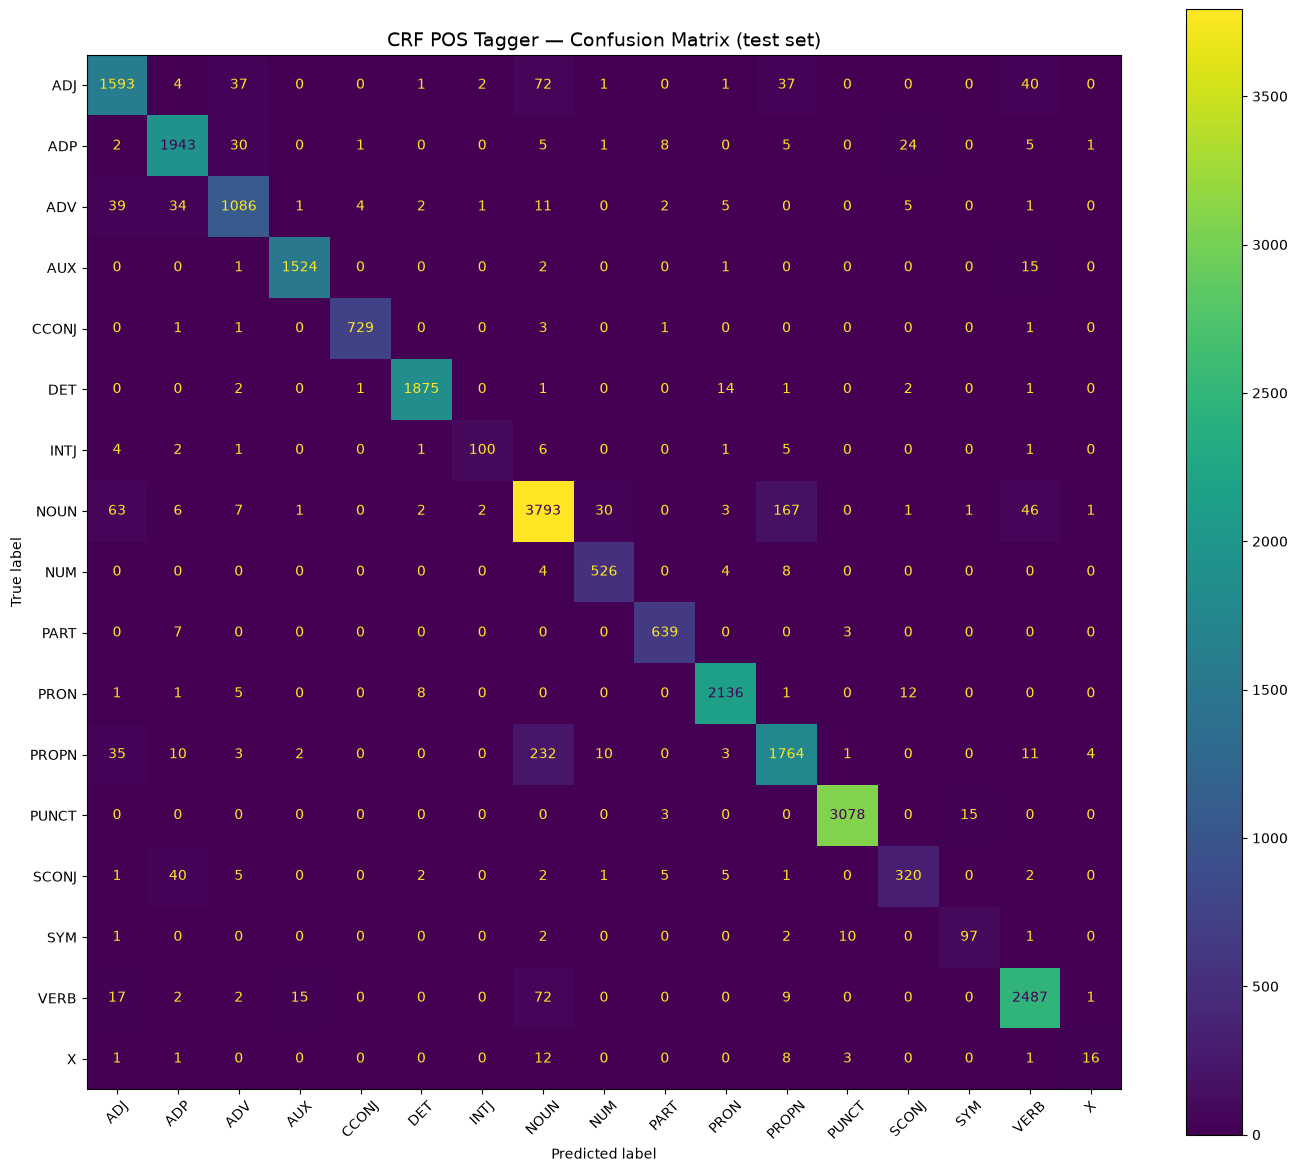

In [11]:
cm = confusion_matrix(gold_flat, pred_flat, labels=TAG_SET)

fig, ax = plt.subplots(figsize=(14, 12))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=TAG_SET)
disp.plot(ax=ax, colorbar=True, xticks_rotation=45, values_format="d")
ax.set_title("CRF POS Tagger — Confusion Matrix (test set)", fontsize=14)
plt.tight_layout()
plt.show()

In [12]:
from collections import Counter
# --- Transition features ---
# crf.transition_features_ maps (label_from, label_to) tuple -> weight float
trans_weights = crf.transition_features_
top_positive_trans = sorted(trans_weights.items(), key=lambda x: x[1], reverse=True)[:10]
top_negative_trans = sorted(trans_weights.items(), key=lambda x: x[1])[:10]
print("Top 10 positive transitions (likely):")
for (f, t), w in top_positive_trans:
    print(f"  {f:>6} → {t:<6}  {w:+.3f}")
print("\nTop 10 negative transitions (unlikely):")
for (f, t), w in top_negative_trans:
    print(f"  {f:>6} → {t:<6}  {w:+.3f}")
# --- State / emission features ---
# crf.state_features_ maps (attr, label) tuple -> weight float
state_weights = crf.state_features_
top_positive_state = sorted(state_weights.items(), key=lambda x: x[1], reverse=True)[:15]
top_negative_state = sorted(state_weights.items(), key=lambda x: x[1])[:15]
print("\nTop 15 positive state features:")
for (attr, label), w in top_positive_state:
    print(f"  {attr!r:40s}  {label:<6}  {w:+.3f}")
print("\nTop 15 negative state features:")
for (attr, label), w in top_negative_state:
    print(f"  {attr!r:40s}  {label:<6}  {w:+.3f}")

Top 10 positive transitions (likely):
       X → X       +5.987
    PART → VERB    +4.123
     DET → NOUN    +3.704
    PRON → VERB    +2.892
     AUX → VERB    +2.725
     ADJ → NOUN    +2.396
   PROPN → PROPN   +2.209
    INTJ → INTJ    +2.187
     NUM → NOUN    +2.000
     ADP → PROPN   +1.827

Top 10 negative transitions (unlikely):
     ADP → VERB    -3.667
     ADP → PART    -3.429
     ADP → AUX     -3.400
     DET → SCONJ   -3.109
    VERB → VERB    -2.654
     DET → AUX     -2.281
     DET → X       -2.247
   SCONJ → PUNCT   -2.222
    PART → DET     -2.197
     ADV → NOUN    -2.170

Top 15 positive state features:
  '0:suffix3:ous'                           ADJ     +6.677
  '0:istitle'                               PROPN   +6.225
  '0:suffix2:ly'                            ADV     +6.115
  '0:lower:interested'                      ADJ     +5.649
  '0:hasdigit'                              NUM     +4.928
  '0:suffix3:ful'                           ADJ     +4.802
  '0:suffix4:l

In [13]:
# Choose an output directory that is writable and visible in the Kaggle output panel.
if Path("/kaggle/working").exists():
    OUT_DIR = Path("/kaggle/working")
elif Path("/content").exists():
    OUT_DIR = Path("/content")
else:
    OUT_DIR = Path(".")

metrics_path = OUT_DIR / "crf_metrics.json"
pred_path    = OUT_DIR / "crf_test_predictions.jsonl"

# --- Metrics ---
metrics_dict = {
    "model": "CRF",
    "test_accuracy": float(crf_accuracy),
    "test_macro_f1": float(crf_macro_f1),
    "train_seconds": float(crf_train_seconds),
    "inference_seconds": float(crf_inference_seconds),
    "tokens_per_second": float(tokens_per_second),
    "best_c1": best_params["c1"],
    "best_c2": best_params["c2"],
    "max_iterations": MAX_ITER,
    "total_test_tokens": total_tokens,
}
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_dict, f, indent=2)

# --- Per-sentence predictions ---
with open(pred_path, "w", encoding="utf-8") as f:
    for words, gold, pred in zip(test_words, y_test, test_pred_seqs):
        record = {
            "words": words,
            "gold_tags": gold,
            "predicted_tags": list(pred),
        }
        f.write(json.dumps(record) + "\n")

print(f"Metrics saved  → {metrics_path}")
print(f"Predictions saved → {pred_path}")

Metrics saved  → crf_metrics.json
Predictions saved → crf_test_predictions.jsonl


In [14]:
with open(metrics_path, "r", encoding="utf-8") as f:
    saved_metrics = json.load(f)

with open(pred_path, "r", encoding="utf-8") as f:
    first_record = json.loads(next(f))

assert saved_metrics["model"] == "CRF"
assert len(first_record["words"]) == len(first_record["gold_tags"])
assert len(first_record["words"]) == len(first_record["predicted_tags"])

print("Sanity checks passed.")
print("First saved record:", first_record)

Sanity checks passed.
First saved record: {'words': ['What', 'if', 'Google', 'Morphed', 'Into', 'GoogleOS', '?'], 'gold_tags': ['PRON', 'SCONJ', 'PROPN', 'VERB', 'ADP', 'PROPN', 'PUNCT'], 'predicted_tags': ['PRON', 'SCONJ', 'PROPN', 'PROPN', 'PROPN', 'PROPN', 'PUNCT']}
